# **Wildfire Ignition Prediction Using Machine Learning and Deep Learning**

## **Objective**

The goal of this project is to predict wildfire ignition events using meteorological and environmental data from the GRIDMET and IRWIN datasets.

This project compares multiple machine learning and deep learning approaches:
- Random Forest
- XGBoost
- LSTM
- GRU

The study also investigates:
- class imbalance
- temporal dependencies
- overfitting behavior
- threshold tuning
- model generalization

## **1. Import Libraries**

In [3]:
import pandas as pd
import numpy as np

## **2. Load and Explore Dataset**

In [4]:
df = pd.read_csv("Wildfire_Dataset.csv", low_memory=False)

df.info()
df.head()
df['Wildfire'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9509925 entries, 0 to 9509924
Data columns (total 19 columns):
 #   Column     Dtype  
---  ------     -----  
 0   latitude   float64
 1   longitude  float64
 2   datetime   object 
 3   Wildfire   object 
 4   pr         float64
 5   rmax       float64
 6   rmin       float64
 7   sph        float64
 8   srad       float64
 9   tmmn       float64
 10  tmmx       float64
 11  vs         float64
 12  bi         float64
 13  fm100      float64
 14  fm1000     float64
 15  erc        float64
 16  etr        float64
 17  pet        float64
 18  vpd        float64
dtypes: float64(17), object(2)
memory usage: 1.3+ GB


Wildfire
No     9007860
Yes     502065
Name: count, dtype: int64

## **3. Data Cleaning and Preprocessing**

### 3.1. Parse Datetime and Sort

In [5]:
df['datetime'] = pd.to_datetime(df['datetime'])

In [6]:
df = df.sort_values(['latitude', 'longitude', 'datetime']).reset_index(drop=True)

### 3.2. Assign Event IDs
Each wildfire event = 75 consecutive rows. We assign a unique event_id every 75 rows.

In [7]:
df['event_id'] = np.arange(len(df)) // 75

In [8]:
df.groupby('event_id').size().value_counts()

75    126799
Name: count, dtype: int64

### 3.4. Feature Aggregation (75 rows to 1 row per event)

In [9]:
features = ['pr','rmax','rmin','sph','srad', 'tmmn','tmmx','vs','bi','fm100','fm1000','erc', 'etr','pet','vpd']

In [10]:
agg_dict = {
    # Fire intensity / heat / dryness features
    'tmmx': ['mean', 'max', 'std'],
    'vpd':  ['mean', 'max', 'std'],
    'erc':  ['mean', 'max', 'std'],
    'bi':   ['mean', 'max', 'std'],

    # Precipitation
    'pr': ['mean', 'max', 'std'],

    # Fuel moisture: low values matter
    'fm100':  ['mean', 'min', 'std'],
    'fm1000': ['mean', 'min', 'std'],

    # Wind
    'vs': ['mean', 'max'],

    # Humidity
    'rmax': ['mean'],
    'rmin': ['mean', 'min'],

    # Other weather/environment features
    'sph':  ['mean'],
    'srad': ['mean'],
    'tmmn': ['mean'],
    'etr':  ['mean'],
    'pet':  ['mean'],

    # Metadata
    'latitude': 'first',
    'longitude': 'first',
    'datetime': 'first',

    # Label
    'Wildfire': lambda x: 1 if (x == 'Yes').any() else 0
}
df_ml = df.groupby('event_id').agg(agg_dict)

In [11]:
df_ml.columns = [
    '_'.join(col).strip('_') if isinstance(col, tuple) else col
    for col in df_ml.columns
]

df_ml = df_ml.reset_index()

In [12]:
df_ml = df_ml.rename(columns={'Wildfire_<lambda>': 'label'})
print(df_ml.shape)
df_ml.head()

(126799, 36)


,event_id,tmmx_mean,tmmx_max,tmmx_std,vpd_mean,vpd_max,vpd_std,erc_mean,erc_max,erc_std,...,rmin_min,sph_mean,srad_mean,tmmn_mean,etr_mean,pet_mean,latitude_first,longitude_first,datetime_first,label
0,0,304.273333,306.9,1.569243,0.892400,1.36,0.212627,21.493333,31.0,7.874649,...,36.7,0.015794,296.205333,293.280000,6.769333,5.573333,25.26027,-80.80099,2014-04-11,0
1,1,304.586667,308.0,1.843933,0.907867,1.33,0.218337,20.626667,30.0,5.897258,...,44.4,0.016528,289.060000,294.516000,6.750667,5.561333,25.26027,-80.80099,2015-04-11,0
2,2,304.274667,308.8,1.845088,0.922000,1.51,0.204748,20.760000,31.0,5.846782,...,29.9,0.016151,298.717333,294.550667,6.816000,5.656000,25.26027,-80.80099,2016-04-10,0
3,3,304.057333,308.2,1.746980,0.877600,1.31,0.228910,18.426667,28.0,7.677931,...,31.0,0.016266,292.168000,294.366667,6.965333,5.641333,25.26027,-80.80099,2017-04-10,0
4,4,303.386667,307.1,2.097124,0.816800,1.37,0.213055,16.453333,29.0,8.741472,...,30.9,0.015943,293.836000,293.977333,6.473333,5.396000,25.26027,-80.80099,2018-04-10,1


In [13]:
df_ml['month'] = df_ml['datetime_first'].dt.month

### 3.5. Check Missing Values

In [14]:
df_ml.isnull().sum().sort_values(ascending=False)

event_id           0
fm1000_mean        0
fm1000_std         0
vs_mean            0
vs_max             0
rmax_mean          0
rmin_mean          0
rmin_min           0
sph_mean           0
srad_mean          0
tmmn_mean          0
etr_mean           0
pet_mean           0
latitude_first     0
longitude_first    0
datetime_first     0
label              0
fm1000_min         0
fm100_std          0
tmmx_mean          0
fm100_min          0
tmmx_max           0
tmmx_std           0
vpd_mean           0
vpd_max            0
vpd_std            0
erc_mean           0
erc_max            0
erc_std            0
bi_mean            0
bi_max             0
bi_std             0
pr_mean            0
pr_max             0
pr_std             0
fm100_mean         0
month              0
dtype: int64

## **4. Bias Analysis**
We examine three types of bias before training: class imbalance, seasonal patterns, and spatial distribution.

### 4.1. Class Imbalance

In [15]:
df_ml['label'].value_counts()

label
0    93514
1    33285
Name: count, dtype: int64

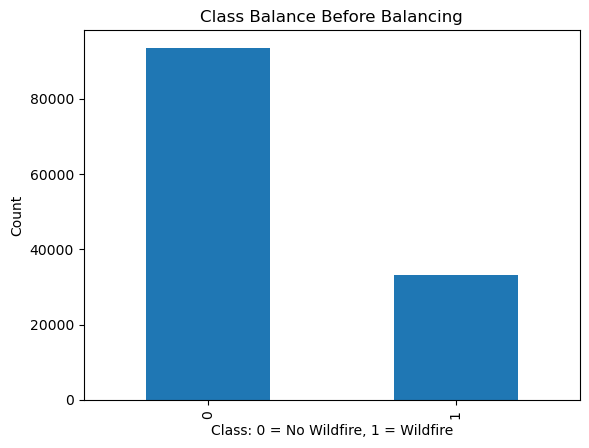

In [16]:
import matplotlib.pyplot as plt
df_ml['label'].value_counts().plot(kind='bar')
plt.title('Class Balance Before Balancing')
plt.xlabel('Class: 0 = No Wildfire, 1 = Wildfire')
plt.ylabel('Count')
plt.show()

### 4.2. Seasonal Bias

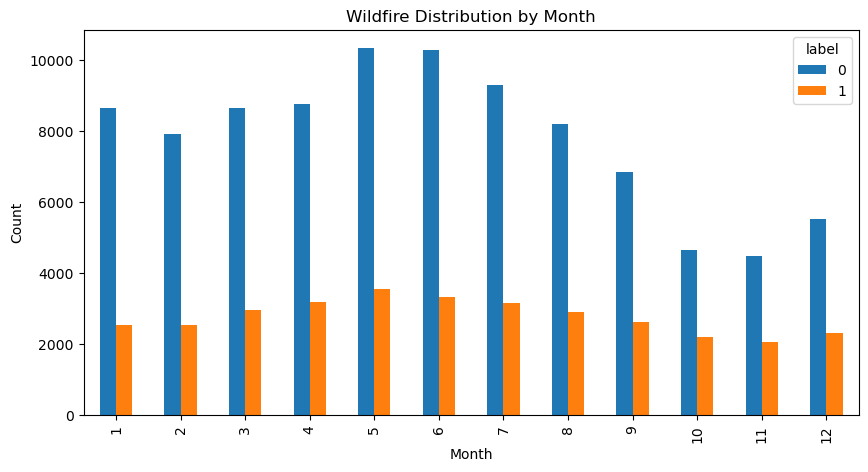

In [17]:
pd.crosstab(df_ml['month'], df_ml['label']).plot(kind='bar', figsize=(10,5))
plt.title('Wildfire Distribution by Month')
plt.xlabel('Month')
plt.ylabel('Count')
plt.show()

### 4.3. Spatial Bias

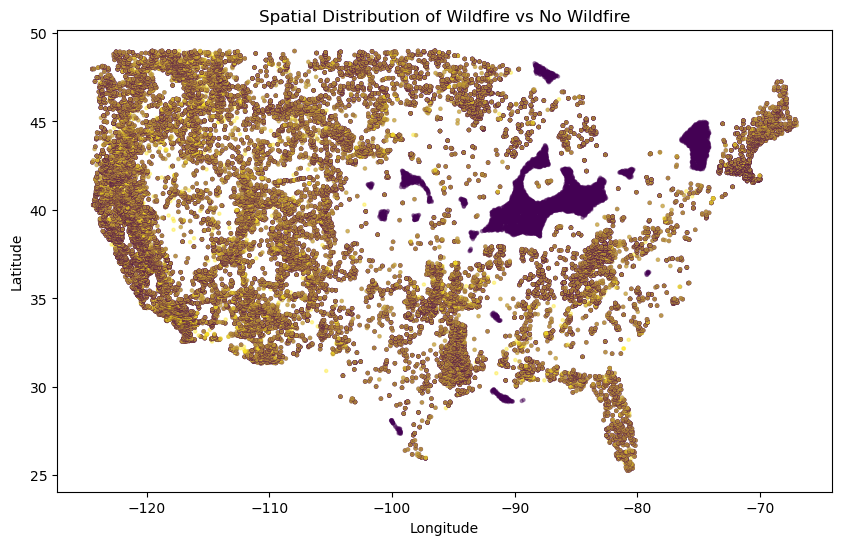

In [18]:
plt.figure(figsize=(10,6))
plt.scatter(
    df_ml['longitude_first'],
    df_ml['latitude_first'],
    c=df_ml['label'],
    alpha=0.4,
    s=5
)
plt.title('Spatial Distribution of Wildfire vs No Wildfire')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

## **5. Balancing and Train/Val/Test Split**

### 5.1. Undersample to 50/50
We keep all fire events and randomly undersample non-fire events to match. Then shuffle to prevent ordering bias.

In [19]:
from sklearn.utils import resample

In [20]:
#balance dataset 50-50
yes_df = df_ml[df_ml['label'] == 1]
no_df = df_ml[df_ml['label'] == 0]
no_downsampled = resample(no_df, replace=False, n_samples=len(yes_df),random_state=42)
df_balanced = pd.concat([yes_df, no_downsampled]) #combine the 0 and 1 rows
df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True) 

In [21]:
df_balanced['label'].value_counts()

label
0    33285
1    33285
Name: count, dtype: int64

### 5.2. Define Features and Target
We drop: latitude, longitude (spatial overfitting), datetime, event_id (no predictive value).

In [22]:
drop_cols = [
    'event_id',
    'label',
    'datetime_first',
    'latitude_first',
    'longitude_first'
]

X = df_balanced.drop(columns=drop_cols)
y = df_balanced['label']

In [23]:
X.shape

(66570, 32)

In [24]:
y.shape

(66570,)

### 5.3. Train/Validation/Test Split (70/15/15)

In [25]:
from sklearn.model_selection import train_test_split

In [26]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y,test_size=0.30, random_state=42, stratify=y)

In [27]:
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp,test_size=0.50,random_state=42,stratify=y_temp)

In [28]:
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (46599, 32)
Validation: (9985, 32)
Test: (9986, 32)


In [26]:
from sklearn.ensemble import RandomForestClassifier

## **6. Random Forest**
**Architecture:** Ensemble of 300 decision trees trained in parallel (n_jobs=-2). Each tree sees a random subset of features at each split (max_features="sqrt"). Final prediction by majority vote.

### 6.1. Baseline Model

In [27]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-2)

In [28]:
rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [29]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [30]:
y_val_pred = rf_model.predict(X_val)

print("Validation Accuracy:", accuracy_score(y_val, y_val_pred))
print("Validation Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))
print("Validation Classification Report:")
print(classification_report(y_val, y_val_pred))

Validation Accuracy: 0.6459689534301453
Validation Confusion Matrix:
[[3356 1637]
 [1898 3094]]
Validation Classification Report:
              precision    recall  f1-score   support

           0       0.64      0.67      0.66      4993
           1       0.65      0.62      0.64      4992

    accuracy                           0.65      9985
   macro avg       0.65      0.65      0.65      9985
weighted avg       0.65      0.65      0.65      9985



### 6.2. Tuned Model (300 trees, regularized depth)

In [31]:
rf_improved = RandomForestClassifier(n_estimators=300,max_depth=25,min_samples_split=5,min_samples_leaf=2,random_state=42,n_jobs=-1)
rf_improved.fit(X_train, y_train)

,n_estimators,300
,criterion,'gini'
,max_depth,25
,min_samples_split,5
,min_samples_leaf,2
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [32]:
y_val_pred2 = rf_improved.predict(X_val)

print("Improved Accuracy:", accuracy_score(y_val, y_val_pred2))
print(confusion_matrix(y_val, y_val_pred2))
print(classification_report(y_val, y_val_pred2))

Improved Accuracy: 0.6462694041061592
[[3288 1705]
 [1827 3165]]
              precision    recall  f1-score   support

           0       0.64      0.66      0.65      4993
           1       0.65      0.63      0.64      4992

    accuracy                           0.65      9985
   macro avg       0.65      0.65      0.65      9985
weighted avg       0.65      0.65      0.65      9985



### 6.3. Threshold Optimization
For wildfire detection, a false negative (missed fire) is more costly than a false alarm. We lower the threshold below 0.5 to improve recall.

In [33]:
y_probs = rf_improved.predict_proba(X_val)[:,1]

y_pred_thresh = (y_probs > 0.4).astype(int)

print(confusion_matrix(y_val, y_pred_thresh))
print(classification_report(y_val, y_pred_thresh))

[[1793 3200]
 [ 629 4363]]
              precision    recall  f1-score   support

           0       0.74      0.36      0.48      4993
           1       0.58      0.87      0.70      4992

    accuracy                           0.62      9985
   macro avg       0.66      0.62      0.59      9985
weighted avg       0.66      0.62      0.59      9985



In [34]:
print("Improved Accuracy:", accuracy_score(y_val, y_pred_thresh))


Improved Accuracy: 0.6165247871807712


### 6.4. Sentinel Value Detection and Cleaning
GRIDMET uses 32,767 (2^15 - 1) as a sentinel for missing data. We detect and replace with column medians.

In [29]:
feat_cols = ['pr','rmax','rmin','sph','srad','tmmn','tmmx',
             'vs','bi','fm100','fm1000','erc','etr','pet','vpd']

contaminated = (df[feat_cols] >= 32000).any(axis=1).sum()
print(f"Contaminated rows: {contaminated:,} out of {len(df):,}")
print(f"Percentage: {contaminated/len(df)*100:.2f}%")

for col in feat_cols:
    bad = (df[col] >= 32000).sum()
    if bad > 0:
        print(f"  {col}: {bad:,} bad values")

Contaminated rows: 25,725 out of 9,509,925
Percentage: 0.27%
  pr: 25,725 bad values
  rmax: 25,725 bad values
  rmin: 25,725 bad values
  sph: 25,725 bad values
  srad: 25,725 bad values
  tmmn: 25,725 bad values
  tmmx: 25,725 bad values
  vs: 25,725 bad values
  bi: 25,725 bad values
  fm100: 25,725 bad values
  fm1000: 25,725 bad values
  erc: 25,725 bad values
  etr: 25,725 bad values
  pet: 25,725 bad values
  vpd: 25,725 bad values


In [30]:
#Clean raw df BEFORE aggregation
df_clean = df.copy()
df_clean[feat_cols] = df_clean[feat_cols].where(
    df_clean[feat_cols] < 32000, other=np.nan
)

for col in feat_cols:
    median_val = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_val)

print("Max values after cleaning:")
print(df_clean[feat_cols].max().sort_values(ascending=False).head(8).round(2))

Max values after cleaning:
pr      528.0
srad    440.6
tmmx    324.3
tmmn    310.0
bi      189.0
erc     121.0
rmax    100.0
rmin    100.0
dtype: float64


### 6.5. Re-aggregate on Clean Data


In [31]:
df_ml_clean = df_clean.groupby('event_id').agg(agg_dict)

df_ml_clean.columns = [
    '_'.join(col).strip('_') if isinstance(col, tuple) else col
    for col in df_ml_clean.columns
]
df_ml_clean = df_ml_clean.reset_index()
df_ml_clean = df_ml_clean.rename(columns={'Wildfire_<lambda>': 'label'})
df_ml_clean['month'] = df_ml_clean['datetime_first'].dt.month

print(df_ml_clean.shape)
print(df_ml_clean[['tmmx_mean','vpd_mean','erc_mean','bi_mean']].describe().round(2))

(126799, 37)
       tmmx_mean   vpd_mean   erc_mean    bi_mean
count  126799.00  126799.00  126799.00  126799.00
mean      294.30       1.13      43.56      33.62
std         8.45       0.71      21.35      16.46
min       262.30       0.05       0.00       0.24
25%       288.77       0.59      25.93      20.80
50%       295.16       0.97      39.12      29.77
75%       300.59       1.51      59.13      43.77
max       317.16       5.49     114.04     100.20


### 6.6. Re-balance and Re-split on Clean Data
Repeat the balancing and splitting steps on sentinel-cleaned data for the final models.

In [32]:
yes_clean = df_ml_clean[df_ml_clean['label'] == 1]
no_clean  = df_ml_clean[df_ml_clean['label'] == 0]
no_down_clean = resample(no_clean, replace=False,
                         n_samples=len(yes_clean), random_state=42)
df_balanced_clean = pd.concat([yes_clean, no_down_clean])\
                    .sample(frac=1, random_state=42).reset_index(drop=True)
X_c = df_balanced_clean.drop(columns=drop_cols)
y_c = df_balanced_clean['label']

X_train_c, X_temp_c, y_train_c, y_temp_c = train_test_split(
    X_c, y_c, test_size=0.30, random_state=42, stratify=y_c)
X_val_c, X_test_c, y_val_c, y_test_c = train_test_split(
    X_temp_c, y_temp_c, test_size=0.50, random_state=42, stratify=y_temp_c)

print(f"Train: {X_train_c.shape}, Val: {X_val_c.shape}, Test: {X_test_c.shape}")

Train: (46599, 32), Val: (9985, 32), Test: (9986, 32)


### 6.7. Retrain on Clean Data

In [39]:
rf_final = RandomForestClassifier(n_estimators=300, max_depth=25,min_samples_split=5, min_samples_leaf=2,random_state=42, n_jobs=-2)
rf_final.fit(X_train_c, y_train_c)

y_val_final = rf_final.predict(X_val_c)
print("Clean RF Validation Accuracy:", accuracy_score(y_val_c, y_val_final))
print(confusion_matrix(y_val_c, y_val_final))
print(classification_report(y_val_c, y_val_final))

Clean RF Validation Accuracy: 0.6452679018527792
[[3287 1706]
 [1836 3156]]
              precision    recall  f1-score   support

           0       0.64      0.66      0.65      4993
           1       0.65      0.63      0.64      4992

    accuracy                           0.65      9985
   macro avg       0.65      0.65      0.65      9985
weighted avg       0.65      0.65      0.65      9985



### 6.8. Feature Importance

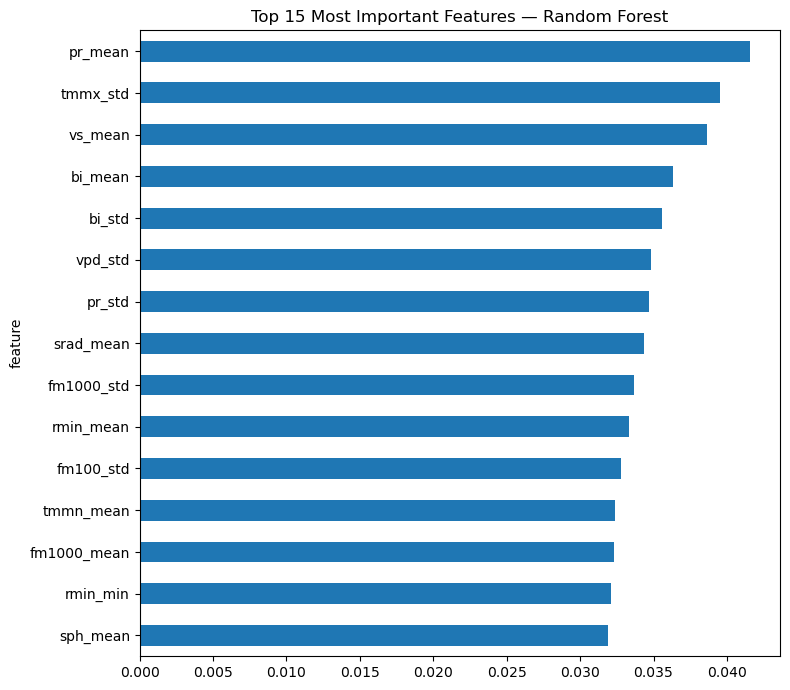

In [40]:
importance_df = pd.DataFrame({
    'feature': X_c.columns,
    'importance': rf_final.feature_importances_
}).sort_values('importance', ascending=False)

importance_df.head(15).plot(
    x='feature', y='importance',
    kind='barh', figsize=(8, 7), legend=False
)
plt.title('Top 15 Most Important Features — Random Forest')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('rf_feature_importance.png', dpi=150)
plt.show()

### 6.9. Threshold Sweep (Clean Data)

In [41]:
y_probs_clean = rf_final.predict_proba(X_val_c)[:, 1]

from sklearn.metrics import f1_score, recall_score, precision_score

print(f"{'Threshold':<12} {'Accuracy':<12} {'Recall(fire)':<15} {'Precision(fire)':<18} {'F1(fire)'}")
for t in [0.5, 0.45, 0.4, 0.35, 0.3]:
    y_t = (y_probs_clean >= t).astype(int)
    print(f"{t:<12.2f} "
          f"{accuracy_score(y_val_c, y_t):<12.3f} "
          f"{recall_score(y_val_c, y_t):<15.3f} "
          f"{precision_score(y_val_c, y_t):<18.3f} "
          f"{f1_score(y_val_c, y_t):.3f}")

Threshold    Accuracy     Recall(fire)    Precision(fire)    F1(fire)
0.50         0.645        0.632           0.649              0.641
0.45         0.631        0.772           0.602              0.677
0.40         0.615        0.873           0.576              0.694
0.35         0.586        0.927           0.551              0.691
0.30         0.563        0.961           0.535              0.687


### 6.10. Final Test Evaluation (Threshold = 0.40)

In [42]:
best_threshold = 0.4
y_test_probs = rf_final.predict_proba(X_test_c)[:, 1]
y_test_final = (y_test_probs >= best_threshold).astype(int)

print("=== FINAL RF TEST RESULTS ===")
print("Accuracy:", accuracy_score(y_test_c, y_test_final))
print(confusion_matrix(y_test_c, y_test_final))
print(classification_report(y_test_c, y_test_final))

=== FINAL RF TEST RESULTS ===
Accuracy: 0.6122571600240336
[[1781 3212]
 [ 660 4333]]
              precision    recall  f1-score   support

           0       0.73      0.36      0.48      4993
           1       0.57      0.87      0.69      4993

    accuracy                           0.61      9986
   macro avg       0.65      0.61      0.59      9986
weighted avg       0.65      0.61      0.59      9986



## **7. XGBOOST** 
**Architecture:** Gradient boosting: builds 300 trees sequentially, each correcting residual errors of the previous. Uses learning_rate=0.05, max_depth=6, subsampling=80%.

### 7.1. Baseline Model

In [44]:
from xgboost import XGBClassifier

xgb_base = XGBClassifier(
    n_estimators=100,
    random_state=42
)

xgb_base.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [45]:
# XGBOOST BASELINE EVALUATION
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_val_pred_base = xgb_base.predict(X_val)

print("Validation Accuracy:", accuracy_score(y_val, y_val_pred_base))
print("Validation Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_base))
print("Validation Classification Report:")
print(classification_report(y_val, y_val_pred_base))

Validation Accuracy: 0.6241362043064597
Validation Confusion Matrix:
[[3158 1835]
 [1918 3074]]
Validation Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.63      0.63      4993
           1       0.63      0.62      0.62      4992

    accuracy                           0.62      9985
   macro avg       0.62      0.62      0.62      9985
weighted avg       0.62      0.62      0.62      9985



### 7.2. Tuned Model

In [46]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


In [47]:
# XGBOOST TUNED EVALUATION
y_val_pred = xgb_model.predict(X_val)

print("Improved Accuracy:", accuracy_score(y_val, y_val_pred))
print(confusion_matrix(y_val, y_val_pred))
print(classification_report(y_val, y_val_pred))

Improved Accuracy: 0.6359539308963446
[[3201 1792]
 [1843 3149]]
              precision    recall  f1-score   support

           0       0.63      0.64      0.64      4993
           1       0.64      0.63      0.63      4992

    accuracy                           0.64      9985
   macro avg       0.64      0.64      0.64      9985
weighted avg       0.64      0.64      0.64      9985



### 7.3. Threshold Experiment

In [48]:
y_probs = xgb_model.predict_proba(X_val)[:, 1]

y_pred_thresh = (y_probs > 0.4).astype(int)

print(confusion_matrix(y_val, y_pred_thresh))
print(classification_report(y_val, y_pred_thresh))

[[1659 3334]
 [ 677 4315]]
              precision    recall  f1-score   support

           0       0.71      0.33      0.45      4993
           1       0.56      0.86      0.68      4992

    accuracy                           0.60      9985
   macro avg       0.64      0.60      0.57      9985
weighted avg       0.64      0.60      0.57      9985



In [49]:
# XGBOOST THRESHOLD ACCURACY
print("Improved Accuracy:", accuracy_score(y_val, y_pred_thresh))

Improved Accuracy: 0.5982974461692538


### 7.4. Retrain on Clean Data

In [50]:
xgb_final = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='logloss'
)

xgb_final.fit(X_train_c, y_train_c)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


In [51]:
# CLEAN XGB VALIDATION
y_val_final = xgb_final.predict(X_val_c)

print("Clean XGB Validation Accuracy:", accuracy_score(y_val_c, y_val_final))
print(confusion_matrix(y_val_c, y_val_final))
print(classification_report(y_val_c, y_val_final))

Clean XGB Validation Accuracy: 0.6342513770655984
[[3192 1801]
 [1851 3141]]
              precision    recall  f1-score   support

           0       0.63      0.64      0.64      4993
           1       0.64      0.63      0.63      4992

    accuracy                           0.63      9985
   macro avg       0.63      0.63      0.63      9985
weighted avg       0.63      0.63      0.63      9985



### 7.5. Feature Importance

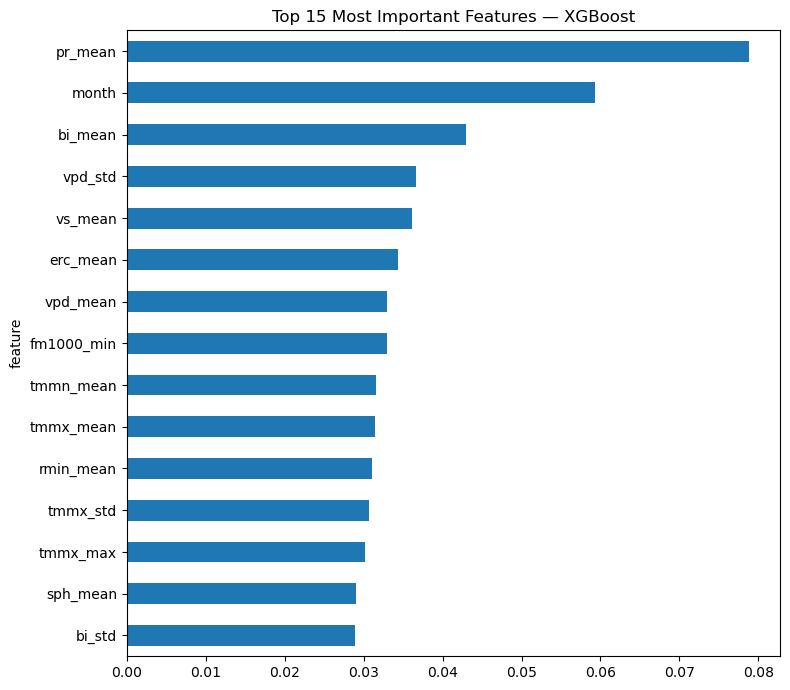

In [52]:
import pandas as pd
import matplotlib.pyplot as plt

importance_df = pd.DataFrame({
    'feature': X_c.columns,
    'importance': xgb_final.feature_importances_
}).sort_values('importance', ascending=False)

importance_df.head(15).plot(
    x='feature',
    y='importance',
    kind='barh',
    figsize=(8,7),
    legend=False
)

plt.title('Top 15 Most Important Features — XGBoost')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### 7.6. Threshold Sweep (Clean Data)

In [53]:
y_probs_clean = xgb_final.predict_proba(X_val_c)[:, 1]

from sklearn.metrics import f1_score, recall_score, precision_score

print(f"{'Threshold':<12} {'Accuracy':<12} {'Recall(fire)':<15} {'Precision(fire)':<18} {'F1(fire)'}")

for t in [0.5, 0.45, 0.4, 0.35, 0.3]:
    y_t = (y_probs_clean >= t).astype(int)
    print(f"{t:<12.2f} "
          f"{accuracy_score(y_val_c, y_t):<12.3f} "
          f"{recall_score(y_val_c, y_t):<15.3f} "
          f"{precision_score(y_val_c, y_t):<18.3f} "
          f"{f1_score(y_val_c, y_t):.3f}")

Threshold    Accuracy     Recall(fire)    Precision(fire)    F1(fire)
0.50         0.634        0.629           0.636              0.632
0.45         0.622        0.771           0.594              0.671
0.40         0.602        0.863           0.567              0.685
0.35         0.580        0.921           0.548              0.687
0.30         0.562        0.953           0.535              0.685


### 7.7. Final Test Evaluation (Threshold = 0.40)

In [54]:
best_threshold = 0.4

y_test_probs = xgb_final.predict_proba(X_test_c)[:, 1]
y_test_final = (y_test_probs >= best_threshold).astype(int)

print("=== FINAL XGB TEST RESULTS ===")
print("Accuracy:", accuracy_score(y_test_c, y_test_final))
print(confusion_matrix(y_test_c, y_test_final))
print(classification_report(y_test_c, y_test_final))

=== FINAL XGB TEST RESULTS ===
Accuracy: 0.6054476266773483
[[1724 3269]
 [ 671 4322]]
              precision    recall  f1-score   support

           0       0.72      0.35      0.47      4993
           1       0.57      0.87      0.69      4993

    accuracy                           0.61      9986
   macro avg       0.64      0.61      0.58      9986
weighted avg       0.64      0.61      0.58      9986



## **8. LSTM (Long Short-Term Memory)**
**Architecture:** Two stacked LSTM layers (128 then 64 units) with BatchNormalization and Dropout (0.3) after each. The first LSTM returns the full sequence; the second collapses it to a vector. Followed by Dense(32) and sigmoid output. Total: 126,145 parameters.

Unlike RF and XGBoost which see averaged features, the LSTM processes all 75 days in sequence and learns temporal patterns preceding ignition.

### 8.1. Sequence Preparation
For DL models we preserve the raw 75-day sequences. Same 50/50 balancing at event level.

In [33]:
from sklearn.preprocessing import StandardScaler

seq_features = ['pr','rmax','rmin','sph','srad','tmmn','tmmx',
                'vs','bi','fm100','fm1000','erc','etr','pet','vpd']

In [34]:
event_label_map = df_clean.groupby('event_id')['Wildfire']\
                  .apply(lambda x: 1 if (x=='Yes').any() else 0)

all_ids = event_label_map.index.values
all_labels = event_label_map.values

fire_ids = all_ids[all_labels == 1]
nofire_ids = all_ids[all_labels == 0]

np.random.seed(42)
nofire_ids_down = np.random.choice(nofire_ids, size=len(fire_ids), replace=False)

balanced_ids = np.concatenate([fire_ids, nofire_ids_down])
np.random.shuffle(balanced_ids)

print(f"Total balanced sequences: {len(balanced_ids)}")
print(f"Fire: {len(fire_ids)}")
print(f"No fire: {len(nofire_ids_down)}")

Total balanced sequences: 66570
Fire: 33285
No fire: 33285


In [35]:
balanced_id_set = set(balanced_ids)

sequences = []
labels_seq = []

for event_id, group in df_clean.groupby('event_id'):
    if event_id not in balanced_id_set:
        continue

    group = group.sort_values('datetime')
    seq = group[seq_features].values
    label = 1 if (group['Wildfire'] == 'Yes').any() else 0

    sequences.append(seq)
    labels_seq.append(label)

X_seq = np.array(sequences)
y_seq = np.array(labels_seq)

print(f"Sequence shape: {X_seq.shape}")
print(f"Label balance: {np.bincount(y_seq)}")

Sequence shape: (66570, 75, 15)
Label balance: [33285 33285]


### 8.2. Split and Normalize Sequences
StandardScaler fitted on training data only applied to val and test to prevent data leakage.

In [36]:
X_seq_tr, X_seq_temp, y_seq_tr, y_seq_temp = train_test_split(
    X_seq, y_seq, test_size=0.30, random_state=42, stratify=y_seq)
X_seq_val, X_seq_test, y_seq_val, y_seq_test = train_test_split(
    X_seq_temp, y_seq_temp, test_size=0.50, random_state=42, stratify=y_seq_temp)

print(f"Train: {X_seq_tr.shape}")
print(f"Val:   {X_seq_val.shape}")
print(f"Test:  {X_seq_test.shape}")

Train: (46599, 75, 15)
Val:   (9985, 75, 15)
Test:  (9986, 75, 15)


In [37]:
# Reshape to 2D to fit scaler, then reshape back
n_tr, timesteps, n_feat = X_seq_tr.shape

scaler_seq = StandardScaler()
X_seq_tr_sc   = scaler_seq.fit_transform(X_seq_tr.reshape(-1, n_feat))\
                           .reshape(n_tr, timesteps, n_feat)
X_seq_val_sc  = scaler_seq.transform(X_seq_val.reshape(-1, n_feat))\
                           .reshape(X_seq_val.shape[0], timesteps, n_feat)
X_seq_test_sc = scaler_seq.transform(X_seq_test.reshape(-1, n_feat))\
                           .reshape(X_seq_test.shape[0], timesteps, n_feat)

print("Scaled train shape:", X_seq_tr_sc.shape)

Scaled train shape: (46599, 75, 15)


### 8.3. Build LSTM

In [60]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from sklearn.utils.class_weight import compute_class_weight

In [49]:
def build_lstm(input_shape):
    inputs = layers.Input(shape=input_shape)
    
    x = layers.LSTM(128, return_sequences=True)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    
    x = layers.LSTM(64)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    
    x = layers.Dense(32, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    
    output = layers.Dense(1, activation='sigmoid')(x)
    return Model(inputs, output)

lstm_model = build_lstm((75, 15))
lstm_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy',tf.keras.metrics.AUC(name='auc'),tf.keras.metrics.Recall(name='recall')]
)
lstm_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 75, 15)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 75, 128)        │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 75, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 75, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 126,145 (492.75 KB)

 Trainable params: 125,697 (491.00 KB)

 Non-trainable params: 448 (1.75 KB)

### 8.4. Train LSTM
Monitors val_auc. EarlyStopping (patience=5) restores best weights. ReduceLROnPlateau halves LR if no improvement for 3 epochs.

In [51]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        patience=5, restore_best_weights=True, monitor='val_auc', mode='max'),
    tf.keras.callbacks.ReduceLROnPlateau(
        patience=3, factor=0.5, monitor='val_auc', mode='max')
]

history = lstm_model.fit(
    X_seq_tr_sc, y_seq_tr,
    validation_data=(X_seq_val_sc, y_seq_val),
    epochs=30,
    batch_size=32,
    callbacks=callbacks
)

Epoch 1/30
1457/1457 ━━━━━━━━━━━━━━━━━━━━ 226s 146ms/step - accuracy: 0.5608 - auc: 0.5816 - loss: 0.6907 - recall: 0.5892 - val_accuracy: 0.5800 - val_auc: 0.6107 - val_loss: 0.6744 - val_recall: 0.5950 - learning_rate: 0.0010
Epoch 2/30
1457/1457 ━━━━━━━━━━━━━━━━━━━━ 215s 147ms/step - accuracy: 0.5689 - auc: 0.5932 - loss: 0.6801 - recall: 0.6179 - val_accuracy: 0.5938 - val_auc: 0.6401 - val_loss: 0.6646 - val_recall: 0.5749 - learning_rate: 0.0010
Epoch 3/30
1457/1457 ━━━━━━━━━━━━━━━━━━━━ 160s 110ms/step - accuracy: 0.5827 - auc: 0.6180 - loss: 0.6706 - recall: 0.6172 - val_accuracy: 0.5942 - val_auc: 0.6469 - val_loss: 0.6573 - val_recall: 0.7987 - learning_rate: 0.0010
Epoch 4/30
1457/1457 ━━━━━━━━━━━━━━━━━━━━ 165s 113ms/step - accuracy: 0.5944 - auc: 0.6336 - loss: 0.6636 - recall: 0.6508 - val_accuracy: 0.6058 - val_auc: 0.6553 - val_loss: 0.6538 - val_recall: 0.6671 - learning_rate: 0.0010
Epoch 5/30
1457/1457 ━━━━━━━━━━━━━━━━━━━━ 185s 127ms/step - accuracy: 0.5949 - auc: 0.63

### 8.5. Threshold Analysis

In [54]:
y_lstm_prob = lstm_model.predict(X_seq_val_sc).flatten()

for t in [0.5, 0.45, 0.4, 0.35]:
    y_pred = (y_lstm_prob >= t).astype(int)
    print(f"\nThreshold: {t}")
    print("Accuracy:", accuracy_score(y_seq_val, y_pred))
    print(confusion_matrix(y_seq_val, y_pred))
    print(classification_report(y_seq_val, y_pred))

313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step

Threshold: 0.5
Accuracy: 0.6649974962443665
[[3146 1847]
 [1498 3494]]
              precision    recall  f1-score   support

           0       0.68      0.63      0.65      4993
           1       0.65      0.70      0.68      4992

    accuracy                           0.66      9985
   macro avg       0.67      0.67      0.66      9985
weighted avg       0.67      0.66      0.66      9985


Threshold: 0.45
Accuracy: 0.6603905858788183
[[2598 2395]
 [ 996 3996]]
              precision    recall  f1-score   support

           0       0.72      0.52      0.61      4993
           1       0.63      0.80      0.70      4992

    accuracy                           0.66      9985
   macro avg       0.67      0.66      0.65      9985
weighted avg       0.67      0.66      0.65      9985


Threshold: 0.4
Accuracy: 0.6447671507260891
[[2112 2881]
 [ 666 4326]]
              precision    recall  f1-score   support

           0       0.76      0.

### 8.6. Final Test Evaluation (Threshold = 0.45)

In [56]:
y_test_prob = lstm_model.predict(X_seq_test_sc).flatten()
y_test_pred = (y_test_prob >= 0.45).astype(int)

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
print("=== FINAL LSTM TEST RESULTS ===")
print("Accuracy:", accuracy_score(y_seq_test, y_test_pred))
print(confusion_matrix(y_seq_test, y_test_pred))
print(classification_report(y_seq_test, y_test_pred))

313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 32ms/step
=== FINAL LSTM TEST RESULTS ===
Accuracy: 0.6497095934308031
[[2505 2488]
 [1010 3983]]
              precision    recall  f1-score   support

           0       0.71      0.50      0.59      4993
           1       0.62      0.80      0.69      4993

    accuracy                           0.65      9986
   macro avg       0.66      0.65      0.64      9986
weighted avg       0.66      0.65      0.64      9986



In [57]:
# Save right after evaluating
lstm_model.save('best_lstm_wildfire_final.keras')
print("Model saved.")

Model saved.


### 8.7. Training Curves

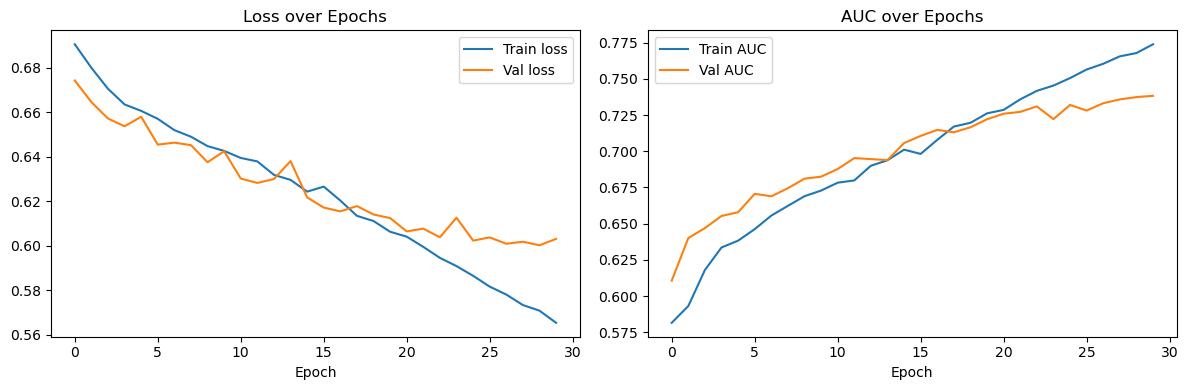

In [58]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history.history['loss'],     label='Train loss')
ax1.plot(history.history['val_loss'], label='Val loss')
ax1.set_title('Loss over Epochs')
ax1.set_xlabel('Epoch')
ax1.legend()

ax2.plot(history.history['auc'],     label='Train AUC')
ax2.plot(history.history['val_auc'], label='Val AUC')
ax2.set_title('AUC over Epochs')
ax2.set_xlabel('Epoch')
ax2.legend()

plt.tight_layout()
plt.savefig('lstm_training_curves.png', dpi=150)
plt.show()

## **9. GRU (Gated Recurrent Unit)**
**Architecture:** Same structure as LSTM but uses GRU layers (reset gate + update gate only, no output gate). Total: 95,937 parameters — 25% fewer than LSTM.

**Overfitting note:** The GRU exhibited more severe overfitting (training AUC ~0.92 vs validation AUC ~0.735) compared to LSTM (gap ~0.10). Despite this, it achieved the highest test accuracy (65.6%) of all four models, suggesting its simpler architecture may offer generalization advantages on this dataset size.

### 9.1. Seed Reset and Build GRU

In [38]:
import random
SEED=42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [62]:
def build_gru(input_shape):
    inputs = layers.Input(shape=input_shape)

    x = layers.GRU(128, return_sequences=True)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)

    x = layers.GRU(64)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Dense(32, activation='relu')(x)
    x = layers.BatchNormalization()(x)

    output = layers.Dense(1, activation='sigmoid')(x)

    return Model(inputs, output)

In [63]:
gru_model = build_gru((75, 15))

gru_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc'), tf.keras.metrics.Recall(name='recall')]
)

gru_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 75, 15)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 75, 128)        │        55,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 75, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 75, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 95,937 (374.75 KB)

 Trainable params: 95,489 (373.00 KB)

 Non-trainable params: 448 (1.75 KB)

### 9.2. Train GRU

In [64]:
callbacks_gru = [
    tf.keras.callbacks.EarlyStopping(
        patience=5,
        restore_best_weights=True,
        monitor='val_auc',
        mode='max'
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        patience=3,
        factor=0.5,
        monitor='val_auc',
        mode='max'
    )
]

history_gru = gru_model.fit(
    X_seq_tr_sc, y_seq_tr,
    validation_data=(X_seq_val_sc, y_seq_val),
    epochs=30,
    batch_size=32,
    callbacks=callbacks_gru
)

Epoch 1/30
1457/1457 ━━━━━━━━━━━━━━━━━━━━ 164s 108ms/step - accuracy: 0.5675 - auc: 0.5942 - loss: 0.6831 - recall: 0.5921 - val_accuracy: 0.5962 - val_auc: 0.6430 - val_loss: 0.6618 - val_recall: 0.5447 - learning_rate: 0.0010
Epoch 2/30
1457/1457 ━━━━━━━━━━━━━━━━━━━━ 160s 110ms/step - accuracy: 0.5911 - auc: 0.6292 - loss: 0.6662 - recall: 0.6401 - val_accuracy: 0.6079 - val_auc: 0.6620 - val_loss: 0.6528 - val_recall: 0.7388 - learning_rate: 0.0010
Epoch 3/30
1457/1457 ━━━━━━━━━━━━━━━━━━━━ 190s 131ms/step - accuracy: 0.6080 - auc: 0.6595 - loss: 0.6503 - recall: 0.6502 - val_accuracy: 0.6280 - val_auc: 0.6894 - val_loss: 0.6317 - val_recall: 0.6745 - learning_rate: 0.0010
Epoch 4/30
1457/1457 ━━━━━━━━━━━━━━━━━━━━ 187s 129ms/step - accuracy: 0.6225 - auc: 0.6785 - loss: 0.6394 - recall: 0.6521 - val_accuracy: 0.6328 - val_auc: 0.7014 - val_loss: 0.6247 - val_recall: 0.6837 - learning_rate: 0.0010
Epoch 5/30
1457/1457 ━━━━━━━━━━━━━━━━━━━━ 174s 120ms/step - accuracy: 0.6348 - auc: 0.69

### 9.3 Threshold Analysis

In [65]:
y_val_prob_gru = gru_model.predict(X_seq_val_sc).flatten()

for t in [0.5, 0.45, 0.4, 0.35]:
    y_pred_gru = (y_val_prob_gru >= t).astype(int)
    print(f"\nThreshold: {t}")
    print("Accuracy:", accuracy_score(y_seq_val, y_pred_gru))
    print(confusion_matrix(y_seq_val, y_pred_gru))
    print(classification_report(y_seq_val, y_pred_gru))

313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 44ms/step

Threshold: 0.5
Accuracy: 0.6789183775663495
[[3421 1572]
 [1634 3358]]
              precision    recall  f1-score   support

           0       0.68      0.69      0.68      4993
           1       0.68      0.67      0.68      4992

    accuracy                           0.68      9985
   macro avg       0.68      0.68      0.68      9985
weighted avg       0.68      0.68      0.68      9985


Threshold: 0.45
Accuracy: 0.6760140210315473
[[3233 1760]
 [1475 3517]]
              precision    recall  f1-score   support

           0       0.69      0.65      0.67      4993
           1       0.67      0.70      0.68      4992

    accuracy                           0.68      9985
   macro avg       0.68      0.68      0.68      9985
weighted avg       0.68      0.68      0.68      9985


Threshold: 0.4
Accuracy: 0.6761141712568853
[[3032 1961]
 [1273 3719]]
              precision    recall  f1-score   support

           0       0.70      0.

### 9.4. Final Test Evaluation (Threshold = 0.40)

In [66]:
best_threshold_gru = 0.4

y_test_prob_gru = gru_model.predict(X_seq_test_sc).flatten()
y_test_pred_gru = (y_test_prob_gru >= best_threshold_gru).astype(int)

print("=== FINAL GRU TEST RESULTS ===")
print("Accuracy:", accuracy_score(y_seq_test, y_test_pred_gru))
print(confusion_matrix(y_seq_test, y_test_pred_gru))
print(classification_report(y_seq_test, y_test_pred_gru))

313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 41ms/step
=== FINAL GRU TEST RESULTS ===
Accuracy: 0.6561185659923894
[[2879 2114]
 [1320 3673]]
              precision    recall  f1-score   support

           0       0.69      0.58      0.63      4993
           1       0.63      0.74      0.68      4993

    accuracy                           0.66      9986
   macro avg       0.66      0.66      0.65      9986
weighted avg       0.66      0.66      0.65      9986



### 9.5. Training Curves

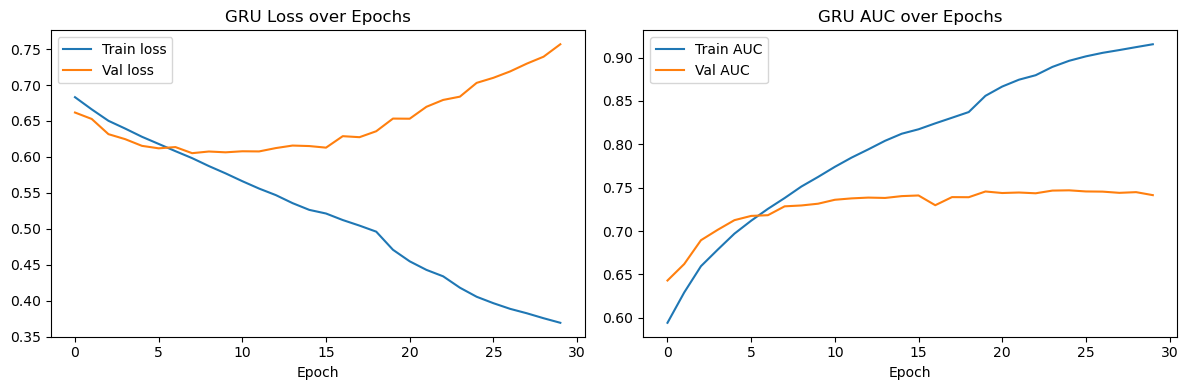

In [67]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history_gru.history['loss'], label='Train loss')
ax1.plot(history_gru.history['val_loss'], label='Val loss')
ax1.set_title('GRU Loss over Epochs')
ax1.set_xlabel('Epoch')
ax1.legend()

ax2.plot(history_gru.history['auc'], label='Train AUC')
ax2.plot(history_gru.history['val_auc'], label='Val AUC')
ax2.set_title('GRU AUC over Epochs')
ax2.set_xlabel('Epoch')
ax2.legend()

plt.tight_layout()
plt.savefig('gru_training_curves.png', dpi=150)
plt.show()

In [71]:
import joblib

# Save GRU
gru_model.save('gru_wildfire_final.keras')

# Save RF
joblib.dump(rf_final, 'rf_wildfire_final.pkl')

# Save XGBoost
joblib.dump(xgb_final, 'xgb_wildfire_final.pkl')

# Save scaler
joblib.dump(scaler_seq, 'scaler_lstm.pkl')

print("All models saved.")

All models saved.


## **10. Model Comparison: ROC and Precision-Recall Curves**
All four models evaluated on the same held-out test set and compared visually.

### 10.1. Load All Models and Generate Probabilities

In [40]:
import joblib
import tensorflow as tf
from tensorflow.keras.models import load_model

rf_final = joblib.load("rf_wildfire_final.pkl")
xgb_final = joblib.load("xgb_wildfire_final.pkl")

lstm_model = load_model("best_lstm_wildfire_final.keras")
gru_model = load_model("gru_wildfire_final.keras")

In [41]:
# ML models
rf_probs = rf_final.predict_proba(X_test_c)[:, 1]
xgb_probs = xgb_final.predict_proba(X_test_c)[:, 1]

# DL models
lstm_probs = lstm_model.predict(X_seq_test_sc).flatten()
gru_probs = gru_model.predict(X_seq_test_sc).flatten()

313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 42ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 48ms/step


### 10.2. ROC Curves

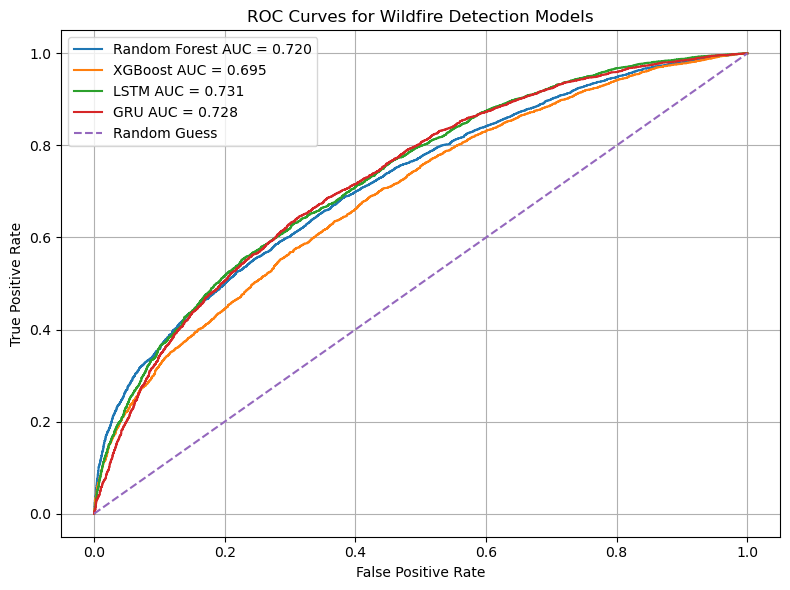

In [42]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

models_probs = {
    "Random Forest": (y_test_c, rf_probs),
    "XGBoost": (y_test_c, xgb_probs),
    "LSTM": (y_seq_test, lstm_probs),
    "GRU": (y_seq_test, gru_probs)
}

plt.figure(figsize=(8,6))

for name, (y_true, probs) in models_probs.items():
    fpr, tpr, _ = roc_curve(y_true, probs)
    auc_score = roc_auc_score(y_true, probs)
    plt.plot(fpr, tpr, label=f"{name} AUC = {auc_score:.3f}")

plt.plot([0,1], [0,1], linestyle="--", label="Random Guess")

plt.title("ROC Curves for Wildfire Detection Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("roc_curves_all_models.png", dpi=150)
plt.show()

### 10.3. Precision-Recall Curves

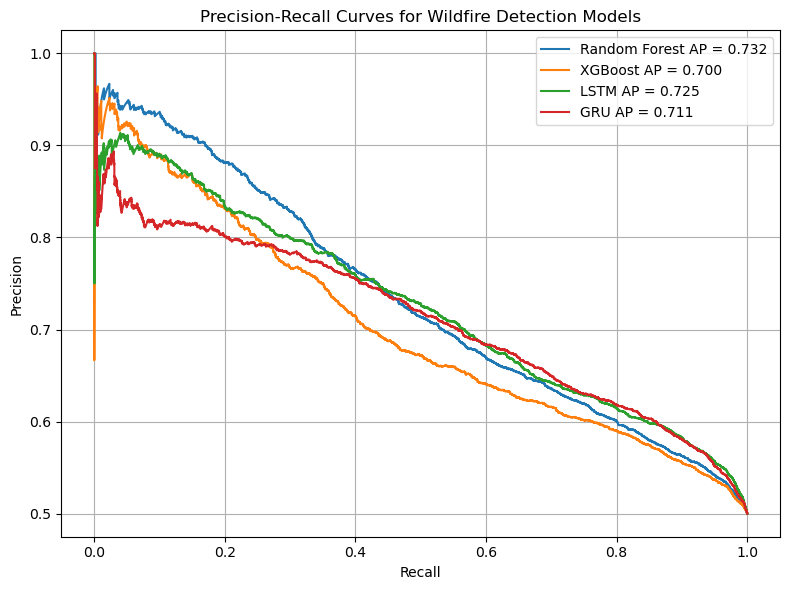

In [43]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(8,6))

for name, (y_true, probs) in models_probs.items():
    precision, recall, _ = precision_recall_curve(y_true, probs)
    ap_score = average_precision_score(y_true, probs)
    plt.plot(recall, precision, label=f"{name} AP = {ap_score:.3f}")

plt.title("Precision-Recall Curves for Wildfire Detection Models")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("precision_recall_curves_all_models.png", dpi=150)
plt.show()

## **11. Final Results Summary**

In [44]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_auc_score
import pandas as pd

final_results = []

model_settings = {
    "Random Forest": (y_test_c, rf_probs, 0.4),
    "XGBoost": (y_test_c, xgb_probs, 0.4),
    "LSTM": (y_seq_test, lstm_probs, 0.45),
    "GRU": (y_seq_test, gru_probs, 0.4)
}

for name, (y_true, probs, threshold) in model_settings.items():
    y_pred = (probs >= threshold).astype(int)

    final_results.append({
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (fire)": precision_score(y_true, y_pred),
        "Recall (fire)": recall_score(y_true, y_pred),
        "F1 (fire)": f1_score(y_true, y_pred),
        "AUC": roc_auc_score(y_true, probs)
    })

results_df = pd.DataFrame(final_results)
results_df

,Model,Threshold,Accuracy,Precision (fire),Recall (fire),F1 (fire),AUC
0,Random Forest,0.40,0.612257,0.574288,0.867815,0.691179,0.719756
1,XGBoost,0.40,0.605448,0.569358,0.865612,0.686904,0.694529
2,LSTM,0.45,0.649710,0.615515,0.797717,0.694871,0.731131
3,GRU,0.40,0.656119,0.634698,0.735630,0.681447,0.728168
